In [1]:
import numpy as np
import pandas as pd
import  matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import(
   accuracy_score,classification_report,confusion_matrix
)

In [3]:
df = pd.read_csv("/home/kinkini/Downloads/dataset/Lesson_04_Supervised_Learning_ Classification_and_its_Application/online_gaming_behavior_dataset.csv")

In [4]:
print(df.shape)

(40034, 13)


In [5]:
print(df.head())

   PlayerID  Age  Gender Location GameGenre  PlayTimeHours  InGamePurchases  \
0      9000   43    Male    Other  Strategy      16.271119                0   
1      9001   29  Female      USA  Strategy       5.525961                0   
2      9002   22  Female      USA    Sports       8.223755                0   
3      9003   35    Male      USA    Action       5.265351                1   
4      9004   33    Male   Europe    Action      15.531945                0   

  GameDifficulty  SessionsPerWeek  AvgSessionDurationMinutes  PlayerLevel  \
0         Medium                6                        108           79   
1         Medium                5                        144           11   
2           Easy               16                        142           35   
3           Easy                9                         85           57   
4         Medium                2                        131           95   

   AchievementsUnlocked EngagementLevel  
0                   

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40034 entries, 0 to 40033
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   PlayerID                   40034 non-null  int64  
 1   Age                        40034 non-null  int64  
 2   Gender                     40034 non-null  str    
 3   Location                   40034 non-null  str    
 4   GameGenre                  40034 non-null  str    
 5   PlayTimeHours              40034 non-null  float64
 6   InGamePurchases            40034 non-null  int64  
 7   GameDifficulty             40034 non-null  str    
 8   SessionsPerWeek            40034 non-null  int64  
 9   AvgSessionDurationMinutes  40034 non-null  int64  
 10  PlayerLevel                40034 non-null  int64  
 11  AchievementsUnlocked       40034 non-null  int64  
 12  EngagementLevel            40034 non-null  str    
dtypes: float64(1), int64(7), str(5)
memory usage: 4.0 MB


In [7]:
#check missing values
print(df.isnull().sum())

PlayerID                     0
Age                          0
Gender                       0
Location                     0
GameGenre                    0
PlayTimeHours                0
InGamePurchases              0
GameDifficulty               0
SessionsPerWeek              0
AvgSessionDurationMinutes    0
PlayerLevel                  0
AchievementsUnlocked         0
EngagementLevel              0
dtype: int64


In [8]:
#check duplicate records
print(df.duplicated().sum())

0


In [9]:
df["EngagementLevel"].value_counts()

EngagementLevel
Medium    19374
High      10336
Low       10324
Name: count, dtype: int64

In [12]:
x = df.drop(
    columns=["PlayerID","EngagementLevel"]
)
y = df["EngagementLevel"]

print("X axis: " , x)
print("Y axis :" , y)

X axis:         Age  Gender Location   GameGenre  PlayTimeHours  InGamePurchases  \
0       43    Male    Other    Strategy      16.271119                0   
1       29  Female      USA    Strategy       5.525961                0   
2       22  Female      USA      Sports       8.223755                0   
3       35    Male      USA      Action       5.265351                1   
4       33    Male   Europe      Action      15.531945                0   
...    ...     ...      ...         ...            ...              ...   
40029   32    Male      USA    Strategy      20.619662                0   
40030   44  Female    Other  Simulation      13.539280                0   
40031   15  Female      USA         RPG       0.240057                1   
40032   34    Male      USA      Sports      14.017818                1   
40033   19    Male      USA      Sports      10.083804                0   

      GameDifficulty  SessionsPerWeek  AvgSessionDurationMinutes  PlayerLevel  \
0        

In [13]:
numerical_features = [
    "Age",
    "PlayTimeHours",
    "InGamePurchases",
    "SessionsPerWeek",
    "AvgSessionDurationMinutes",
    "PlayerLevel",
    "AchievementsUnlocked"
]

In [14]:
categorical_features = [
    "Gender",
    "Location",
    "GameGenre",
    "GameDifficulty"
]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (32027, 11)
Testing data: (8007, 11)


In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

In [17]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

In [18]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

In [19]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

In [20]:
model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [21]:
y_pred = model.predict(X_test)

print(y_pred[:10])

['Medium' 'Low' 'High' 'Medium' 'Medium' 'Low' 'Low' 'High' 'Medium' 'Low']


In [22]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

Accuracy: 0.8927188709878856
Accuracy percentage: 89.27188709878855 %


In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.89      0.87      0.88      2067
         Low       0.87      0.89      0.88      2065
      Medium       0.91      0.91      0.91      3875

    accuracy                           0.89      8007
   macro avg       0.89      0.89      0.89      8007
weighted avg       0.89      0.89      0.89      8007



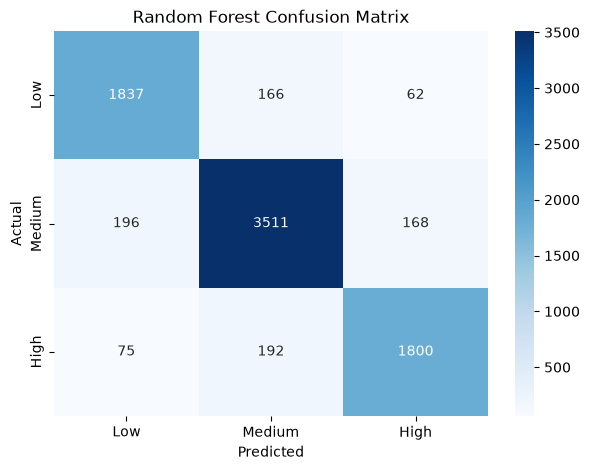

In [24]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest Confusion Matrix")

plt.show()

In [26]:
feature_names = (
    model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importances = (
    model.named_steps["classifier"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(10))

                                 Feature  Importance
17            remainder__SessionsPerWeek    0.372431
18  remainder__AvgSessionDurationMinutes    0.302259
15              remainder__PlayTimeHours    0.062786
19                remainder__PlayerLevel    0.060517
20       remainder__AchievementsUnlocked    0.057146
14                        remainder__Age    0.049558
16            remainder__InGamePurchases    0.007784
5                      cat__Location_USA    0.007428
11              cat__GameDifficulty_Easy    0.007009
3                   cat__Location_Europe    0.006960


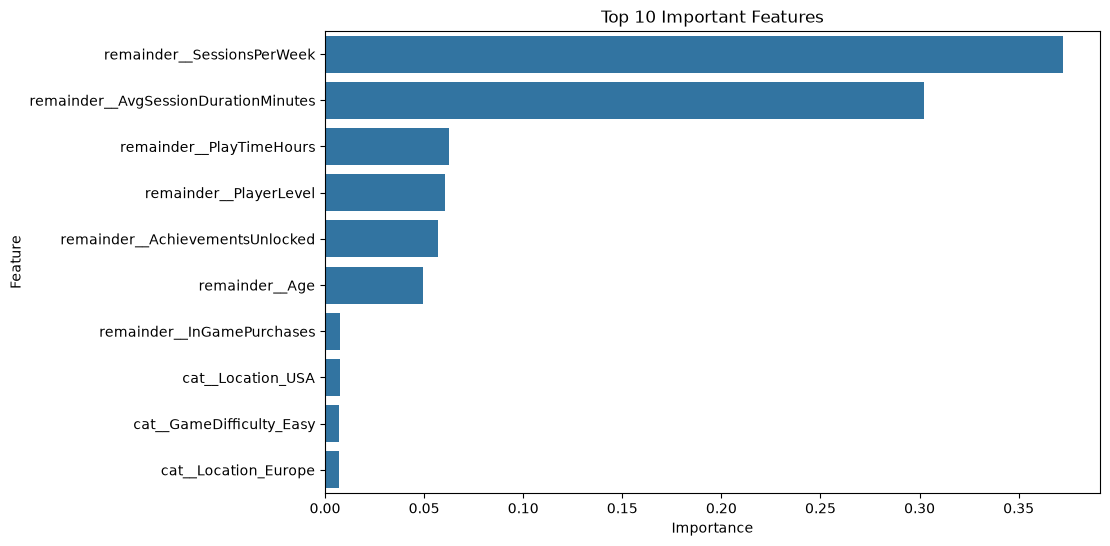

In [27]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features")
plt.show()

In [28]:
new_player = pd.DataFrame([{
    "Age": 22,
    "Gender": "Female",
    "Location": "USA",
    "GameGenre": "Sports",
    "PlayTimeHours": 15.5,
    "InGamePurchases": 1,
    "GameDifficulty": "Medium",
    "SessionsPerWeek": 12,
    "AvgSessionDurationMinutes": 120,
    "PlayerLevel": 45,
    "AchievementsUnlocked": 30
}])

prediction = model.predict(new_player)

print("Predicted Engagement:", prediction[0])

Predicted Engagement: High


In [29]:
probabilities = model.predict_proba(new_player)

for class_name, probability in zip(
    model.classes_,
    probabilities[0]
):
    print(f"{class_name}: {probability * 100:.2f}%")

High: 81.00%
Low: 5.00%
Medium: 14.00%
